Ian Pope (700717419) CS5720 HW2 Pt.2

Q1. Implement Convolution from Scratch

In [ ]:
import numpy as np

In [ ]:
#Initialize numpy arrays for matrix and filter
input = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0]
])

filter = np.array([
    [1, 0, 1],
    [0, 1, 0],
    [1, 0, 1]
])

#This is where I would apply padding but since it is 0, we will skip

#Initialize an output array of size 3x3 (since we know what the dimensions will be)
output = np.zeros((3, 3), dtype=int)

In [ ]:
#Slide the filter over the input
for i in range(0, 3):
  for j in range(0, 3):

    #Get the region the filter is looking at (for stride 1, output 3x3)
    conv_region = input[i : i + 3, j : j + 3]

    #Calculate the dot product and add to output matrix
    output[i, j] = np.sum(conv_region * filter)

#Print the output feature map
print("Output Feature Map: \n", output)

#Print the output feature shape
print("\nOutput Shape:", output.shape)

Output Feature Map: 
 [[4 3 4]
 [2 4 3]
 [2 3 4]]

Output Shape: (3, 3)


f. Briefly explain how changing the stride from 1 to 2 would affect the output  
(This answer is also in the assignment document)  
Changing the stride from 1 to 2 would cause the convolutional layer to process less sections and reduce the size of the output. In this case, it would leave a 2x2 matrix of [[4, 4], [2, 4]]

Q2: Transfer Learning: Freeze vs. Fine-Tune

In [ ]:
#Import libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import time

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [ ]:
#Import the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step
Training images: (50000, 32, 32, 3)
Test images: (10000, 32, 32, 3)


In [ ]:
#Define class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

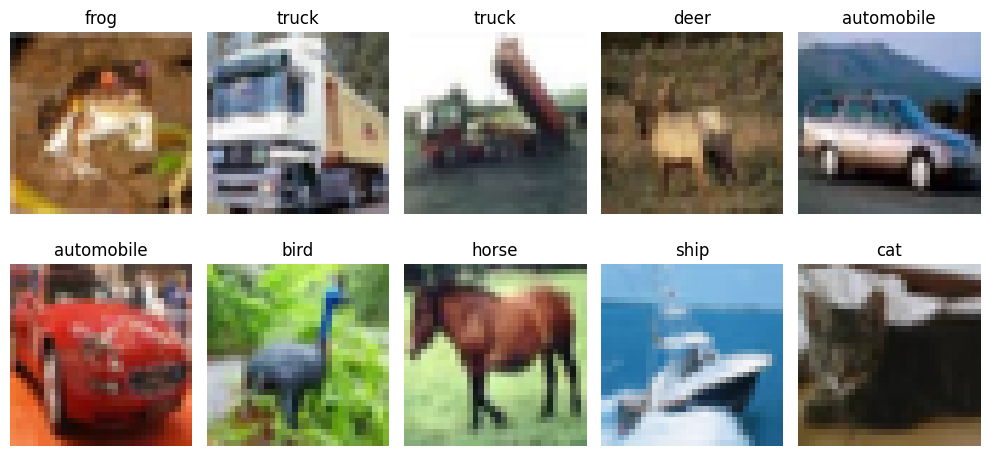

In [ ]:
#Can remove but can see the images
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:
#Set up a preprcoessing function so we can batch preprocess and resize photos
img_size = 224
batch_size = 32

def preprocess_images(images):
    images = tf.image.resize(images, (img_size, img_size))
    images = preprocess_input(images)
    return images

#Set up data to br preprocessed as needed in batches
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))

train_ds = (
    train_ds
    .shuffle(10000)
    .map(lambda x, y: (preprocess_images(x), y),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    test_ds
    .map(lambda x, y: (preprocess_images(x), y),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
#Load base VGG16 model (without the original classification layer)
base_model = VGG16(weights="imagenet", include_top=False, input_shape=(img_size, img_size, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#Freeze base model layers
base_model.trainable = False

In [ ]:
#Experiment A
#Add a new classifier
model_a = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax") #For out 10 classes
])

In [ ]:
#Compile the model with new classification layers
model_a.compile(tf.keras.optimizers.Adam(learning_rate=0.0001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
#Get the number of trainable paramters
model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
#Train model A and count the time
epochs = 3
start_time_a = time.time()

history_a = model_a.fit(
    train_ds,
    epochs=epochs,
    validation_data=test_ds
)

end_time_a = time.time()

training_time_a = end_time_a - start_time_a


Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 405s 259ms/step - accuracy: 0.6205 - loss: 1.1414 - val_accuracy: 0.7884 - val_loss: 0.6386
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 455s 267ms/step - accuracy: 0.7490 - loss: 0.7341 - val_accuracy: 0.8203 - val_loss: 0.5327
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 418s 268ms/step - accuracy: 0.7915 - loss: 0.6099 - val_accuracy: 0.8365 - val_loss: 0.4848


NameError: name 'training_time_A' is not defined

In [ ]:
#Can ignore error above
#Print time spent training
print(f"Experiment A training time: {training_time_a:.2f} seconds")

Experiment A training time: 1301.39 seconds


In [ ]:
#Get test accuracy for model A
test_loss_a, test_accuracy_a = model_a.evaluate(test_ds)
print(f"Experiment A test accuracy: {test_accuracy_a * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 65s 207ms/step - accuracy: 0.8365 - loss: 0.4848
Experiment A test accuracy: 83.65%


In [ ]:
#Get second base model
base_model_b = VGG16(weights="imagenet", include_top=False, input_shape=(img_size, img_size, 3))

#Freeze all layers
base_model_b.trainable = False

In [ ]:
#Unfreeze the final convolutional layer
for layer in base_model_b.layers:
    if layer.name.startswith("block5"):
        layer.trainable = True

In [ ]:
#Build Model B
model_b = models.Sequential([
    base_model_b,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax")
])

#Compile the model with new classification layers
model_b.compile(tf.keras.optimizers.Adam(learning_rate=0.0001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

In [ ]:
#Get the number of trainable paramters
model_b.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 7,213,322 (27.52 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [ ]:
#Train Model B and record time
start_time_b = time.time()

history_b = model_b.fit(
    train_ds,
    epochs=epochs,
    validation_data=test_ds
)

end_time_b = time.time()
training_time_b = end_time_b - start_time_b

print(f"Experiment B training time: {training_time_b:.2f} seconds")

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 479s 304ms/step - accuracy: 0.7753 - loss: 0.6815 - val_accuracy: 0.8902 - val_loss: 0.3288
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 465s 298ms/step - accuracy: 0.9040 - loss: 0.2972 - val_accuracy: 0.9018 - val_loss: 0.3046
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 464s 297ms/step - accuracy: 0.9389 - loss: 0.1918 - val_accuracy: 0.9044 - val_loss: 0.3097
Experiment B training time: 1408.30 seconds


In [ ]:
#Get model B test accuracy
test_loss_b, test_accuracy_b = model_b.evaluate(test_ds)
print(f"Experiment B test accuracy: {test_accuracy_b * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 71s 227ms/step - accuracy: 0.9044 - loss: 0.3097
Experiment B test accuracy: 90.44%


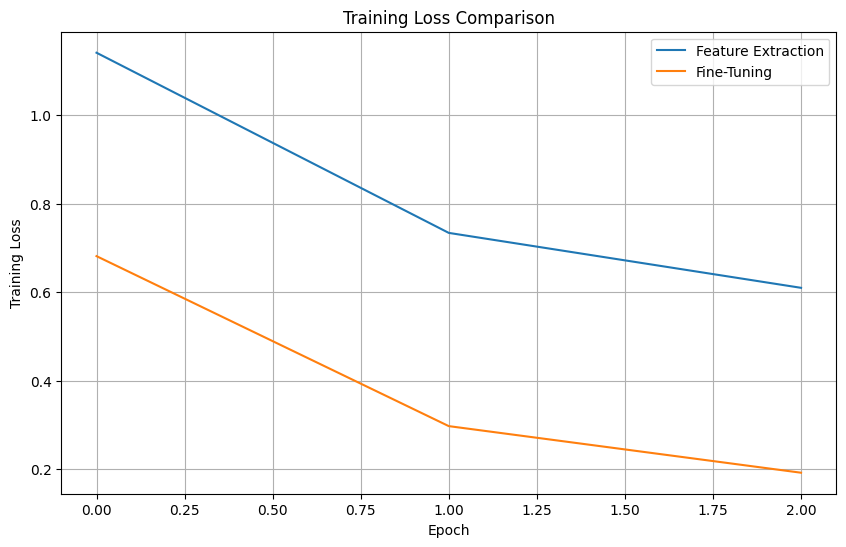

In [ ]:
#Plot training loss
plt.figure(figsize=(10, 6))

plt.plot(
    history_a.history["loss"],
    label="Feature Extraction"
)

plt.plot(
    history_b.history["loss"],
    label="Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
#Print table of results
print("                  Method | Trainable Parameters | Training Time | Accuracy")
print("Frozen Feature Extractor |              133,898 | 1301 seconds  | 83.65%")
print("      Fine-Tuned Network |            7,213,322 | 1408 seconds  | 90.44%")

                  Method | Trainable Parameters | Training Time | Accuracy
Frozen Feature Extractor |              133,898 | 1301 seconds  | 83.65%
      Fine-Tuned Network |            7,213,322 | 1408 seconds  | 90.44%


Q2. g) Explain why freezing layers and fine-tuning layers may produce different training times and performance  
(This answer is also available on the assignment document)  
During the training, I observed a significant increase in accuracy, but also a moderate increase in training time from the Fine-Tuned Network as opposed to the Frozen Feature Extractor. Fine-tuning a layer as opposed to freezing a layer or layers can have significant impacts on the model, largely due to the number of trainable parameters. For my experiment, the number of parameters being trained was over fifty times higher. Because of the increase in parameters, this means that the model has to do significantly more computations to modify all of the parameters. However, because there were so many more parameters, the Fine-Tuned Network was able to more easily conform to the target dataset, leading to higher accuracy.